# MU Capstone v5 — Walk-Forward Forecasting & Feature Audit

เป้าหมายเวอร์ชันนี้ไม่ใช่ทำให้คะแนนดูดีด้วยการตัดข้อมูลผิดปกติ แต่ตรวจว่าโมเดล generalize ได้จริงหรือไม่ โดยเพิ่ม technical features ที่เป็นอัตราส่วน, สร้าง financial growth/margin features, เปรียบเทียบ baseline หลายแบบ และใช้ temporal validation พร้อม purge ข้อมูลที่ target ล้ำข้ามช่วงเวลา

**สำคัญ:** ไม่รับประกันว่าจะชนะตลาด ผลต้องรันจริงและตรวจ test set ก่อนสรุป

## 1. ติดตั้งและนำเข้าไลบรารี

In [ ]:
!pip -q install openpyxl

import os, ast, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

## 2. อัปโหลดไฟล์ 6 ไฟล์
อัปโหลด `mu_prices.csv`, `cleaned_macro_data.csv`, `mu_income_statement_raw.csv`, `mu_earnings_raw.csv`, `mu_cash_flow_raw.csv`, `mu_balance_sheet_raw.csv` พร้อมกัน

In [ ]:
uploaded = files.upload()

def find_file(keyword):
    matches = [f for f in uploaded if keyword.lower() in f.lower() and f.lower().endswith('.csv')]
    if not matches:
        raise FileNotFoundError(f"ไม่พบไฟล์ที่มีคำว่า {keyword}")
    return matches[0]

price_file = find_file('mu_prices')
macro_file = find_file('cleaned_macro_data')
income_file = find_file('mu_income_statement_raw')
earnings_file = find_file('mu_earnings_raw')
cash_file = find_file('mu_cash_flow_raw')
balance_file = find_file('mu_balance_sheet_raw')

prices = pd.read_csv(price_file)
macro = pd.read_csv(macro_file)
income_raw = pd.read_csv(income_file)
earnings_raw = pd.read_csv(earnings_file)
cash_raw = pd.read_csv(cash_file)
balance_raw = pd.read_csv(balance_file)

print('Prices:', prices.shape, '| Macro:', macro.shape)
print('Statement files loaded:', [income_file, earnings_file, cash_file, balance_file])

Saving mu_income_statement_raw.csv to mu_income_statement_raw.csv
Saving mu_balance_sheet_raw.csv to mu_balance_sheet_raw.csv
Saving mu_cash_flow_raw.csv to mu_cash_flow_raw.csv
Saving mu_earnings_raw.csv to mu_earnings_raw.csv
Saving mu_prices.csv to mu_prices.csv
Saving cleaned_macro_data.csv to cleaned_macro_data.csv
Prices: (1255, 8) | Macro: (81, 6)
Statement files loaded: ['mu_income_statement_raw.csv', 'mu_earnings_raw.csv', 'mu_cash_flow_raw.csv', 'mu_balance_sheet_raw.csv']


## 3. แปลงรายงานการเงินที่เก็บเป็นข้อความให้เป็นตาราง
ไฟล์ raw เก็บรายงานเป็น string รูปแบบ Python list/dict จึงใช้ `ast.literal_eval` แทน `json.loads`

In [ ]:
def parse_report_cell(raw_df, column):
    value = raw_df.loc[0, column]
    if pd.isna(value) or not str(value).strip():
        return pd.DataFrame()
    parsed = ast.literal_eval(str(value))
    return pd.DataFrame(parsed)

income_q = parse_report_cell(income_raw, 'quarterlyReports')
earnings_q = parse_report_cell(earnings_raw, 'quarterlyEarnings')
cash_q = parse_report_cell(cash_raw, 'quarterlyReports')
balance_q = parse_report_cell(balance_raw, 'quarterlyReports')

for name, table in [('income', income_q), ('earnings', earnings_q), ('cashflow', cash_q), ('balance', balance_q)]:
    print(name, table.shape, 'date range:', table.get('fiscalDateEnding', pd.Series(dtype=str)).min(), 'to', table.get('fiscalDateEnding', pd.Series(dtype=str)).max())

income (81, 26) date range: 2006-08-31 to 2026-08-31
earnings (123, 7) date range: 1996-02-29 to 2026-08-31
cashflow (81, 30) date range: 2006-08-31 to 2026-08-31
balance (81, 38) date range: 2006-08-31 to 2026-08-31


## 4. สร้าง Feature จากผลประกอบการรายไตรมาส
ใช้ตัวแปรพื้นฐานที่มีความหมายทางธุรกิจ ไม่ใช้คอลัมน์ทุกตัวแบบสุ่ม และตัดตัวแปรที่ไม่มีข้อมูลออก

In [ ]:
def prep_statement(table, prefix, keep_cols):
    if table.empty:
        return pd.DataFrame(columns=['fiscalDateEnding'])
    out = table[['fiscalDateEnding'] + [c for c in keep_cols if c in table.columns]].copy()
    out['fiscalDateEnding'] = pd.to_datetime(out['fiscalDateEnding'], errors='coerce')
    for c in out.columns:
        if c != 'fiscalDateEnding':
            out[c] = pd.to_numeric(out[c].replace({'None': np.nan, 'none': np.nan, '': np.nan}), errors='coerce')
            out = out.rename(columns={c: f'{prefix}_{c}'})
    return out.dropna(subset=['fiscalDateEnding']).sort_values('fiscalDateEnding')

income_keep = ['totalRevenue','grossProfit','operatingIncome','netIncome','researchAndDevelopment',
               'operatingExpenses','incomeBeforeTax','ebitda','costOfRevenue']
cash_keep = ['operatingCashflow','capitalExpenditures','profitLoss','cashflowFromInvestment','cashflowFromFinancing']
balance_keep = ['totalAssets','totalCurrentAssets','cashAndCashEquivalentsAtCarryingValue',
                'cashAndShortTermInvestments','inventory','totalLiabilities','currentDebt','longTermDebt',
                'shortLongTermDebtTotal','totalShareholderEquity']

iq = prep_statement(income_q, 'is', income_keep)
cq = prep_statement(cash_q, 'cf', cash_keep)
bq = prep_statement(balance_q, 'bs', balance_keep)
eq = earnings_q.copy()
eq['fiscalDateEnding'] = pd.to_datetime(eq['fiscalDateEnding'], errors='coerce')
for c in ['reportedEPS','estimatedEPS','surprise','surprisePercentage']:
    if c in eq.columns:
        eq[c] = pd.to_numeric(eq[c], errors='coerce')
if 'reportedDate' in eq.columns:
    eq['reportedDate'] = pd.to_datetime(eq['reportedDate'], errors='coerce')
eq = eq[['fiscalDateEnding'] + [c for c in ['reportedDate','reportedEPS','estimatedEPS','surprise','surprisePercentage'] if c in eq.columns]]
eq = eq.sort_values('fiscalDateEnding').drop_duplicates('fiscalDateEnding', keep='last')

fin = iq.merge(cq, on='fiscalDateEnding', how='outer').merge(bq, on='fiscalDateEnding', how='outer').merge(eq, on='fiscalDateEnding', how='left')
# Use actual earnings announcement date where available; otherwise conservative fallback.
fin['available_date'] = fin['reportedDate']
fin['available_date'] = fin['available_date'].fillna(fin['fiscalDateEnding'] + pd.Timedelta(days=60))
fin = fin.dropna(subset=['available_date']).sort_values('available_date')

# Ratios and changes can be more stable than raw scale-dependent values.
if 'is_totalRevenue' in fin:
    fin['fin_revenue_qoq'] = fin['is_totalRevenue'].pct_change().replace([np.inf, -np.inf], np.nan)
if 'is_grossProfit' in fin and 'is_totalRevenue' in fin:
    fin['fin_gross_margin'] = fin['is_grossProfit'] / fin['is_totalRevenue'].replace(0, np.nan)
if 'cf_operatingCashflow' in fin and 'cf_capitalExpenditures' in fin:
    fin['fin_approx_fcf'] = fin['cf_operatingCashflow'] - fin['cf_capitalExpenditures'].abs()

exclude = {'fiscalDateEnding','reportedDate','available_date'}
fin_features = [c for c in fin.columns if c not in exclude and pd.api.types.is_numeric_dtype(fin[c]) and fin[c].notna().any()]
fin = fin[['available_date'] + fin_features].rename(columns={'available_date':'date'})
print('Quarterly financial records:', len(fin))
print('Financial features:', fin_features)
display(fin.tail(8))

Quarterly financial records: 81
Financial features: ['is_totalRevenue', 'is_grossProfit', 'is_operatingIncome', 'is_netIncome', 'is_researchAndDevelopment', 'is_operatingExpenses', 'is_incomeBeforeTax', 'is_ebitda', 'is_costOfRevenue', 'cf_operatingCashflow', 'cf_capitalExpenditures', 'cf_cashflowFromInvestment', 'cf_cashflowFromFinancing', 'bs_totalAssets', 'bs_totalCurrentAssets', 'bs_cashAndCashEquivalentsAtCarryingValue', 'bs_cashAndShortTermInvestments', 'bs_inventory', 'bs_totalLiabilities', 'bs_longTermDebt', 'bs_shortLongTermDebtTotal', 'bs_totalShareholderEquity', 'reportedEPS', 'estimatedEPS', 'surprise', 'surprisePercentage', 'fin_revenue_qoq', 'fin_gross_margin', 'fin_approx_fcf']


,date,is_totalRevenue,is_grossProfit,is_operatingIncome,is_netIncome,is_researchAndDevelopment,is_operatingExpenses,is_incomeBeforeTax,is_ebitda,is_costOfRevenue,cf_operatingCashflow,cf_capitalExpenditures,cf_cashflowFromInvestment,cf_cashflowFromFinancing,bs_totalAssets,bs_totalCurrentAssets,bs_cashAndCashEquivalentsAtCarryingValue,bs_cashAndShortTermInvestments,bs_inventory,bs_totalLiabilities,bs_longTermDebt,bs_shortLongTermDebtTotal,bs_totalShareholderEquity,reportedEPS,estimatedEPS,surprise,surprisePercentage,fin_revenue_qoq,fin_gross_margin,fin_approx_fcf
73,2024-12-18,8709000000,3348000000,2174000000,1870000000,906000000,1174000000,2153000000,4301000000,5361000000,3244000000,3206000000,-3148000000,-422000000,71461000000,24493000000,6693000000,6693000000,8705000000,24664000000,1.120000e+10,14373000000,46797000000,1.79,1.77,0.02,1.1299,0.123742,0.384430,38000000
74,2025-03-20,8053000000,2963000000,1773000000,1583000000,898000000,1190000000,1760000000,3951000000,5090000000,3942000000,3206000000,-3152000000,96000000,73053000000,24689000000,7552000000,7552000000,9007000000,24420000000,1.154100e+10,15023000000,48633000000,1.56,1.28,0.28,21.8750,-0.075324,0.367937,736000000
75,2025-06-25,9301000000,3508000000,2169000000,1885000000,965000000,1339000000,2113000000,4330000000,5793000000,4609000000,2938000000,-2589000000,540000000,78397000000,27919000000,10163000000,10163000000,8727000000,27649000000,1.243400e+10,16141000000,50748000000,1.91,1.59,0.32,20.1258,0.154973,0.377164,1671000000
76,2025-09-23,11315000000,5054000000,3754000000,3201000000,1029000000,1300000000,3637000000,5910000000,6261000000,5730000000,5658000000,-5198000000,-1064000000,82798000000,28841000000,9642000000,9642000000,8355000000,28633000000,1.153300e+10,15278000000,54165000000,3.03,2.86,0.17,5.9441,0.216536,0.446664,72000000
77,2025-12-17,13643000000,7646000000,6136000000,5240000000,1171000000,1510000000,6069000000,8347000000,5997000000,8411000000,5389000000,-4594000000,-3745000000,85971000000,29665000000,8813000000,8813000000,8205000000,27165000000,8.844000e+09,12493000000,58806000000,4.78,3.94,0.84,21.3198,0.205745,0.560434,3022000000
78,2026-03-18,23860000000,17755000000,16135000000,13785000000,1250000000,1620000000,16156000000,18478000000,6105000000,11903000000,5389000000,-5525000000,-2167000000,101509000000,41413000000,12540000000,12540000000,8267000000,29050000000,7.342000e+09,10798000000,72459000000,12.20,9.31,2.89,31.0419,0.748882,0.744132,6514000000
79,2026-06-24,41456000000,35056000000,33318000000,28243000000,1316000000,1738000000,33221000000,35576000000,6400000000,25388000000,7826000000,-9569000000,-4734000000,134112000000,66737000000,24995000000,24995000000,8567000000,33388000000,3.052000e+09,6376000000,100724000000,25.11,20.98,4.13,19.6854,0.737469,0.845619,17562000000
80,2026-09-30,54229000000,47047000000,44318000000,37701000000,1913000000,2729000000,44284000000,47009000000,7182000000,43973000000,17165000000,-41953000000,11276000000,195888000000,91070000000,38364000000,38364000000,10372000000,57510000000,NaN,5179000000,138378000000,33.19,31.41,1.78,5.6670,0.308110,0.867562,26808000000


## 5. ทำความสะอาดราคาและตรวจจุดเปลี่ยนผิดปกติ

Price rows: 1255 | date range: 2021-10-12 to 2026-10-12


,date,close,daily_return,stock_splits
49,2021-12-21,88.549026,0.105449,0.0
613,2024-03-21,108.962868,0.141298,0.0
743,2024-09-26,109.193268,0.147332,0.0
802,2024-12-19,86.643143,-0.161790,0.0
812,2025-01-06,98.878998,0.104484,0.0
825,2025-01-27,90.760292,-0.117066,0.0
872,2025-04-03,74.151070,-0.160948,0.0
873,2025-04-04,64.555527,-0.129405,0.0
876,2025-04-09,77.672096,0.188129,0.0
877,2025-04-10,69.871979,-0.100424,0.0


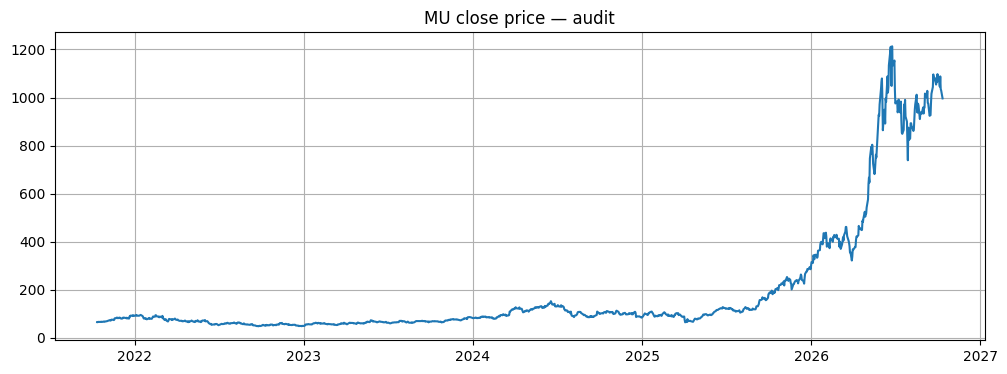

In [ ]:
prices['date'] = pd.to_datetime(prices['date'], utc=True).dt.tz_convert(None).dt.normalize()
prices = prices.sort_values('date').drop_duplicates('date').reset_index(drop=True)
for c in ['open','high','low','close','volume','dividends','stock_splits']:
    if c in prices:
        prices[c] = pd.to_numeric(prices[c], errors='coerce')
prices = prices.dropna(subset=['date','close']).query('close > 0').copy()
prices['daily_return'] = prices['close'].pct_change()
print('Price rows:', len(prices), '| date range:', prices.date.min().date(), 'to', prices.date.max().date())
display(prices.loc[prices.daily_return.abs() > 0.10, ['date','close','daily_return','stock_splits']])
plt.figure(figsize=(12,4)); plt.plot(prices.date, prices.close); plt.title('MU close price — audit'); plt.grid(True); plt.show()

## 6. สร้าง Target และ Features ที่เสถียรกว่า

หลีกเลี่ยงการใช้ระดับราคา OHLC ดิบเป็น feature หลัก เพราะ scale เปลี่ยนตามเวลา ใช้ผลตอบแทน, อัตราส่วน OHLC, momentum, volatility, RSI, MACD, drawdown และ volume ratio แทน

In [ ]:
# Rebuild features using information available at each close.
df = prices.copy().sort_values('date').reset_index(drop=True)
# Ratios / returns, rather than raw nominal price levels
for lag in [1, 2, 3, 5, 10, 21, 42, 63, 126]:
    df[f'return_{lag}d'] = df['close'].pct_change(lag)
for w in [5, 10, 20, 50, 100, 200]:
    ma = df['close'].rolling(w).mean()
    df[f'ma_ratio_{w}'] = df['close'] / ma - 1
    df[f'volatility_{w}'] = df['close'].pct_change().rolling(w).std()
# Daily candle shape / range
for c in ['open','high','low']:
    df[f'{c}_to_close'] = df[c] / df['close'] - 1
if {'high','low'}.issubset(df.columns):
    df['intraday_range'] = (df['high'] - df['low']) / df['close']
# RSI-14
change = df['close'].diff()
gain = change.clip(lower=0).rolling(14).mean()
loss = (-change.clip(upper=0)).rolling(14).mean()
rs = gain / loss.replace(0, np.nan)
df['rsi_14'] = 100 - (100 / (1 + rs))
# MACD scaled by price
ema12 = df['close'].ewm(span=12, adjust=False).mean()
ema26 = df['close'].ewm(span=26, adjust=False).mean()
df['macd_ratio'] = (ema12 - ema26) / df['close']
# Drawdown and volume signals
roll_max = df['close'].rolling(63).max()
df['drawdown_63d'] = df['close'] / roll_max - 1
df['log_volume'] = np.log1p(df['volume'].clip(lower=0))
df['volume_ratio_20d'] = df['volume'] / df['volume'].rolling(20).median().replace(0, np.nan)
df['volume_change_5d'] = df['volume'].pct_change(5).replace([np.inf,-np.inf],np.nan)

HORIZONS = {'1m': 21, '3m': 63, '6m': 126}
for label, h in HORIZONS.items():
    future_close = df['close'].shift(-h)
    df[f'target_log_return_{label}'] = np.log(future_close / df['close'])
    df[f'target_close_{label}'] = future_close
    df[f'target_date_{label}'] = df['date'].shift(-h)

technical_features = [c for c in df.columns if c.startswith((
    'return_','ma_ratio_','volatility_')) or c in [
    'open_to_close','high_to_close','low_to_close','intraday_range','rsi_14',
    'macd_ratio','drawdown_63d','log_volume','volume_ratio_20d','volume_change_5d']]
print('Technical features:', len(technical_features))
display(df[['date','close'] + technical_features[-8:]].tail())

Technical features: 31


,date,close,low_to_close,intraday_range,rsi_14,macd_ratio,drawdown_63d,log_volume,volume_ratio_20d,volume_change_5d
1250,2026-10-06,1045.560059,-0.000287,0.027784,68.151179,0.028832,-0.047230,16.896558,0.982933,0.104350
1251,2026-10-07,1088.000000,-0.070386,0.071507,67.302389,0.028131,-0.008557,17.244955,1.392614,-0.007835
1252,2026-10-08,1035.839966,-0.003611,0.054449,53.007379,0.025542,-0.056088,17.213727,1.349797,-0.346006
1253,2026-10-09,1029.000000,-0.011662,0.036122,47.601495,0.021729,-0.062321,16.803856,0.895909,-0.273789
1254,2026-10-12,996.515991,-0.018079,0.024254,32.946077,0.016360,-0.091922,16.482387,0.651922,-0.211742


## 7. รวม Macro และ Financial Features โดยระวัง Leakage

- เลื่อน macro ไปช่วงเดือนถัดไปเป็น proxy แบบระมัดระวัง (ยังไม่เท่ากับข้อมูล release-vintage จริง)
- งบการเงินจะถูกใช้หลังวันที่ประกาศ หรือ fiscal end + 60 วันเมื่อไม่มี reported date
- เพิ่ม growth / margin / leverage proxy; raw accounting levels จะถูกแปลงเป็น log magnitude เพื่อช่วยลดปัญหา scale

In [ ]:
# Prepare macro data and apply a conservative one-month availability lag.
macro['date'] = pd.to_datetime(macro['date'], errors='coerce').dt.normalize()
macro = macro.dropna(subset=['date']).sort_values('date').drop_duplicates('date')
macro_cols = [c for c in macro.columns if c != 'date']
for c in macro_cols:
    macro[c] = pd.to_numeric(macro[c], errors='coerce')
macro['date'] = macro['date'] + pd.offsets.MonthBegin(1)
# Add macro changes so model can learn direction, not only levels.
for c in macro_cols:
    macro[f'{c}_chg1'] = macro[c].pct_change().replace([np.inf,-np.inf],np.nan)
    macro[f'{c}_chg3'] = macro[c].pct_change(3).replace([np.inf,-np.inf],np.nan)
macro_feature_cols = [c for c in macro.columns if c != 'date']

# Parse and prepare quarterly statements.
def prep_statement(table, prefix, keep_cols):
    if table.empty or 'fiscalDateEnding' not in table:
        return pd.DataFrame(columns=['fiscalDateEnding'])
    out = table[['fiscalDateEnding'] + [c for c in keep_cols if c in table.columns]].copy()
    out['fiscalDateEnding'] = pd.to_datetime(out['fiscalDateEnding'], errors='coerce')
    for c in list(out.columns):
        if c == 'fiscalDateEnding':
            continue
        out[c] = pd.to_numeric(out[c].replace({'None':np.nan,'none':np.nan,'':np.nan}), errors='coerce')
        out = out.rename(columns={c:f'{prefix}_{c}'})
    return out.dropna(subset=['fiscalDateEnding']).sort_values('fiscalDateEnding').drop_duplicates('fiscalDateEnding',keep='last')

income_keep = ['totalRevenue','grossProfit','operatingIncome','netIncome','researchAndDevelopment','operatingExpenses','incomeBeforeTax','ebitda','costOfRevenue']
cash_keep = ['operatingCashflow','capitalExpenditures','profitLoss','cashflowFromInvestment','cashflowFromFinancing']
balance_keep = ['totalAssets','totalCurrentAssets','cashAndCashEquivalentsAtCarryingValue','cashAndShortTermInvestments','inventory','totalLiabilities','currentDebt','longTermDebt','shortLongTermDebtTotal','totalShareholderEquity']
iq = prep_statement(income_q, 'is', income_keep)
cq = prep_statement(cash_q, 'cf', cash_keep)
bq = prep_statement(balance_q, 'bs', balance_keep)
eq = earnings_q.copy()
eq['fiscalDateEnding'] = pd.to_datetime(eq['fiscalDateEnding'], errors='coerce')
for c in ['reportedEPS','estimatedEPS','surprise','surprisePercentage']:
    if c in eq: eq[c] = pd.to_numeric(eq[c], errors='coerce')
if 'reportedDate' in eq: eq['reportedDate'] = pd.to_datetime(eq['reportedDate'], errors='coerce')
eq = eq[['fiscalDateEnding'] + [c for c in ['reportedDate','reportedEPS','estimatedEPS','surprise','surprisePercentage'] if c in eq.columns]]
eq = eq.sort_values('fiscalDateEnding').drop_duplicates('fiscalDateEnding',keep='last')
fin = iq.merge(cq,on='fiscalDateEnding',how='outer').merge(bq,on='fiscalDateEnding',how='outer').merge(eq,on='fiscalDateEnding',how='left')
fin['available_date'] = fin.get('reportedDate', pd.Series(pd.NaT,index=fin.index))
fin['available_date'] = fin['available_date'].fillna(fin['fiscalDateEnding'] + pd.Timedelta(days=60))
fin = fin.dropna(subset=['available_date']).sort_values('available_date').drop_duplicates('available_date',keep='last')

# Financial feature engineering: margins, cash conversion, leverage, quarterly and YoY growth.
if {'is_grossProfit','is_totalRevenue'}.issubset(fin.columns):
    fin['fin_gross_margin'] = fin['is_grossProfit'] / fin['is_totalRevenue'].replace(0,np.nan)
if {'is_operatingIncome','is_totalRevenue'}.issubset(fin.columns):
    fin['fin_operating_margin'] = fin['is_operatingIncome'] / fin['is_totalRevenue'].replace(0,np.nan)
if {'is_netIncome','is_totalRevenue'}.issubset(fin.columns):
    fin['fin_net_margin'] = fin['is_netIncome'] / fin['is_totalRevenue'].replace(0,np.nan)
if {'cf_operatingCashflow','cf_capitalExpenditures'}.issubset(fin.columns):
    fin['fin_approx_fcf'] = fin['cf_operatingCashflow'] - fin['cf_capitalExpenditures'].abs()
if {'bs_totalLiabilities','bs_totalAssets'}.issubset(fin.columns):
    fin['fin_liabilities_assets'] = fin['bs_totalLiabilities'] / fin['bs_totalAssets'].replace(0,np.nan)
if {'bs_totalShareholderEquity','bs_totalAssets'}.issubset(fin.columns):
    fin['fin_equity_assets'] = fin['bs_totalShareholderEquity'] / fin['bs_totalAssets'].replace(0,np.nan)
for c in ['is_totalRevenue','is_grossProfit','is_operatingIncome','is_netIncome','cf_operatingCashflow','fin_approx_fcf']:
    if c in fin:
        fin[f'{c}_qoq'] = fin[c].pct_change().replace([np.inf,-np.inf],np.nan)
        fin[f'{c}_yoy'] = fin[c].pct_change(4).replace([np.inf,-np.inf],np.nan)
# Drop dates and raw values with no usable observations; log-transform raw scale-dependent accounting magnitudes.
exclude = {'fiscalDateEnding','reportedDate','available_date'}
raw_fin_cols = [c for c in fin.columns if c not in exclude and pd.api.types.is_numeric_dtype(fin[c]) and fin[c].notna().any()]
for c in raw_fin_cols:
    if c.startswith(('is_','cf_','bs_')) and not c.endswith(('_qoq','_yoy')):
        # signed log transform keeps sign and reduces scale range
        fin[f'{c}_signed_log'] = np.sign(fin[c]) * np.log1p(np.abs(fin[c]))
fin_features = [c for c in fin.columns if c not in exclude and c != 'fiscalDateEnding' and pd.api.types.is_numeric_dtype(fin[c]) and fin[c].notna().any()]
fin = fin[['available_date'] + fin_features].rename(columns={'available_date':'date'}).sort_values('date')

# As-of joins: only the latest already-available record on each date.
df = pd.merge_asof(df.sort_values('date'), macro[['date']+macro_feature_cols].sort_values('date'), on='date', direction='backward')
df = pd.merge_asof(df.sort_values('date'), fin.sort_values('date'), on='date', direction='backward')
macro_features = [c for c in macro_feature_cols if c in df.columns]
financial_features = [c for c in fin_features if c in df.columns]
feature_sets = {
    'A_price_only': technical_features,
    'B_price_macro': technical_features + macro_features,
    'C_price_macro_financials': technical_features + macro_features + financial_features
}
for name, cols in feature_sets.items():
    print(name, 'feature count:', len([c for c in cols if c in df.columns]))
print('Financial features:', len(financial_features), '| rows:', len(df))

A_price_only feature count: 31
B_price_macro feature count: 46
C_price_macro_financials feature count: 112
Financial features: 66 | rows: 1255


## 8. Walk-forward validation และ baseline ที่เข้มขึ้น

- ใช้ข้อมูลเรียงตามเวลา ไม่สุ่ม train/test
- เลือกโมเดลจากหลาย validation windows ก่อน test
- purge training rows ที่ target date ล้ำเข้า validation/test
- ทดสอบเทียบ 3 baseline: zero-return, historical mean return และ momentum (ผลตอบแทนย้อนหลัง 21 วัน)
- ประเมิน RMSE/MAE ของ log return และ Directional Accuracy

หมายเหตุ: horizon 3/6 เดือนมี target ซ้อนทับกันใน daily test; ควรอ่านคะแนนเป็นการประเมินรายวันแบบ overlapping ไม่ใช่จำนวนการเดิมพันอิสระ

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

models = {
    'Ridge': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler()),('model',Ridge(alpha=30.0))]),
    'RandomForest': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('model',RandomForestRegressor(n_estimators=400,min_samples_leaf=8,max_features=0.7,random_state=42,n_jobs=-1))]),
    'ExtraTrees': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('model',ExtraTreesRegressor(n_estimators=400,min_samples_leaf=8,max_features=0.7,random_state=42,n_jobs=-1))]),
    'HistGradientBoosting': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('model',HistGradientBoostingRegressor(max_iter=150,learning_rate=0.03,max_leaf_nodes=15,l2_regularization=5.0,random_state=42))])
}
def calc_metrics(y, pred):
    y=np.asarray(y); pred=np.asarray(pred)
    return {'MAE_log_return':mean_absolute_error(y,pred),
            'RMSE_log_return':mean_squared_error(y,pred)**0.5,
            'directional_accuracy':float(np.mean(np.sign(y)==np.sign(pred)))}

results=[]; prediction_frames=[]; cv_frames=[]
for horizon, h in HORIZONS.items():
    target=f'target_log_return_{horizon}'; target_date=f'target_date_{horizon}'
    usable=df.dropna(subset=[target,target_date]).sort_values('date').reset_index(drop=True)
    n=len(usable); test_start_pos=int(n*0.80)
    test_start=usable.loc[test_start_pos,'date']
    pretest=usable.iloc[:test_start_pos].copy()
    test=usable.iloc[test_start_pos:].copy()
    # Purge all pre-test examples whose future target overlaps the test period.
    pretest=pretest[pretest[target_date] < test_start].copy()
    if len(pretest)<400 or len(test)<30:
        print('Skipping',horizon,'because split is too small'); continue
    for set_name, feature_list in feature_sets.items():
        cols=[c for c in feature_list if c in usable.columns and pretest[c].notna().any()]
        if not cols: continue
        # Expanding-window validation folds; purge each fold by target date.
        fold_scores={m:[] for m in models}
        tscv=TimeSeriesSplit(n_splits=4)
        for fold,(tr_idx,va_idx) in enumerate(tscv.split(pretest)):
            tr=pretest.iloc[tr_idx].copy(); va=pretest.iloc[va_idx].copy()
            va_start=va['date'].min()
            tr=tr[tr[target_date] < va_start]
            if len(tr)<150 or len(va)<25: continue
            for model_name, estimator in models.items():
                m=clone(estimator); m.fit(tr[cols],tr[target]); pred=m.predict(va[cols])
                fold_scores[model_name].append(mean_squared_error(va[target],pred)**0.5)
        avg_scores={k:float(np.mean(v)) for k,v in fold_scores.items() if len(v)>=2}
        if not avg_scores:
            print('No valid CV folds',horizon,set_name); continue
        best_name=min(avg_scores,key=avg_scores.get)
        # Fit selected model on all pre-test data; test remains untouched.
        final=clone(models[best_name]); final.fit(pretest[cols],pretest[target])
        pred=final.predict(test[cols])
        # Baselines: no change, historical mean drift, and simple momentum.
        base_zero=np.zeros(len(test))
        hist_mean=float(pretest[target].mean())
        base_mean=np.full(len(test),hist_mean)
        momentum_col='return_21d'
        base_mom=test[momentum_col].fillna(0).to_numpy() if momentum_col in test else base_zero.copy()
        baseline_map={'zero':base_zero,'historical_mean':base_mean,'momentum_21d':base_mom}
        scores=calc_metrics(test[target],pred)
        baseline_scores={name:calc_metrics(test[target],bp) for name,bp in baseline_map.items()}
        best_base=min(baseline_scores,key=lambda k:baseline_scores[k]['RMSE_log_return'])
        results.append({'horizon':horizon,'feature_set':set_name,'best_model':best_name,'n_features':len(cols),
            'n_pretest':len(pretest),'n_test':len(test),'cv_rmse_mean':avg_scores[best_name],
            **{f'model_{k}':v for k,v in scores.items()},
            'best_baseline':best_base,
            'best_baseline_RMSE_log_return':baseline_scores[best_base]['RMSE_log_return'],
            'beats_best_baseline_RMSE':scores['RMSE_log_return'] < baseline_scores[best_base]['RMSE_log_return']})
        pf=test[['date','close',target,f'target_close_{horizon}',target_date]].copy()
        pf['predicted_log_return']=pred; pf['predicted_close']=pf['close']*np.exp(pred)
        for bname,bpred in baseline_map.items(): pf[f'pred_{bname}']=bpred
        pf['horizon']=horizon; pf['feature_set']=set_name; pf['model']=best_name
        prediction_frames.append(pf)
        for mn,vals in fold_scores.items():
            for fi,score in enumerate(vals): cv_frames.append({'horizon':horizon,'feature_set':set_name,'model':mn,'fold':fi+1,'validation_RMSE':score})

results_df=pd.DataFrame(results)
if not results_df.empty:
    results_df=results_df.sort_values(['horizon','model_RMSE_log_return'])
predictions_df=pd.concat(prediction_frames,ignore_index=True) if prediction_frames else pd.DataFrame()
cv_df=pd.DataFrame(cv_frames)
display(results_df)


,horizon,feature_set,best_model,n_features,n_pretest,n_test,cv_rmse_mean,model_MAE_log_return,model_RMSE_log_return,model_directional_accuracy,best_baseline,best_baseline_RMSE_log_return,beats_best_baseline_RMSE
1,1m,B_price_macro,RandomForest,46,966,247,0.130133,0.250831,0.307892,0.372470,historical_mean,0.248078,False
2,1m,C_price_macro_financials,RandomForest,112,966,247,0.132576,0.262509,0.322434,0.364372,historical_mean,0.248078,False
0,1m,A_price_only,RandomForest,31,966,247,0.135374,0.317348,0.374661,0.352227,historical_mean,0.248078,False
3,3m,A_price_only,ExtraTrees,31,890,239,0.206162,0.511452,0.567970,0.447699,historical_mean,0.553263,False
5,3m,C_price_macro_financials,HistGradientBoosting,112,890,239,0.193971,0.569593,0.621855,0.301255,historical_mean,0.553263,False
4,3m,B_price_macro,HistGradientBoosting,46,890,239,0.191957,0.599061,0.662377,0.171548,historical_mean,0.553263,False
8,6m,C_price_macro_financials,HistGradientBoosting,112,777,226,0.393868,1.236092,1.255431,0.000000,momentum_21d,0.918750,False
6,6m,A_price_only,Ridge,31,777,226,0.307938,1.749557,1.784575,0.013274,momentum_21d,0.918750,False
7,6m,B_price_macro,Ridge,46,777,226,0.213799,1.950480,1.988233,0.000000,momentum_21d,0.918750,False


## 9. ตรวจ Test และกราฟ

อย่าตัดสินโมเดลจากราคาที่คาดการณ์เพียงเส้นเดียว ให้ดูผลตอบแทนจริงเทียบ prediction, baseline ที่ดีที่สุด และ Directional Accuracy ด้วย

,horizon,feature_set,best_model,n_features,cv_rmse_mean,model_RMSE_log_return,best_baseline,best_baseline_RMSE_log_return,model_directional_accuracy,beats_best_baseline_RMSE
1,1m,B_price_macro,RandomForest,46,0.130133,0.307892,historical_mean,0.248078,0.372470,False
2,1m,C_price_macro_financials,RandomForest,112,0.132576,0.322434,historical_mean,0.248078,0.364372,False
0,1m,A_price_only,RandomForest,31,0.135374,0.374661,historical_mean,0.248078,0.352227,False
3,3m,A_price_only,ExtraTrees,31,0.206162,0.567970,historical_mean,0.553263,0.447699,False
5,3m,C_price_macro_financials,HistGradientBoosting,112,0.193971,0.621855,historical_mean,0.553263,0.301255,False
4,3m,B_price_macro,HistGradientBoosting,46,0.191957,0.662377,historical_mean,0.553263,0.171548,False
8,6m,C_price_macro_financials,HistGradientBoosting,112,0.393868,1.255431,momentum_21d,0.918750,0.000000,False
6,6m,A_price_only,Ridge,31,0.307938,1.784575,momentum_21d,0.918750,0.013274,False
7,6m,B_price_macro,Ridge,46,0.213799,1.988233,momentum_21d,0.918750,0.000000,False


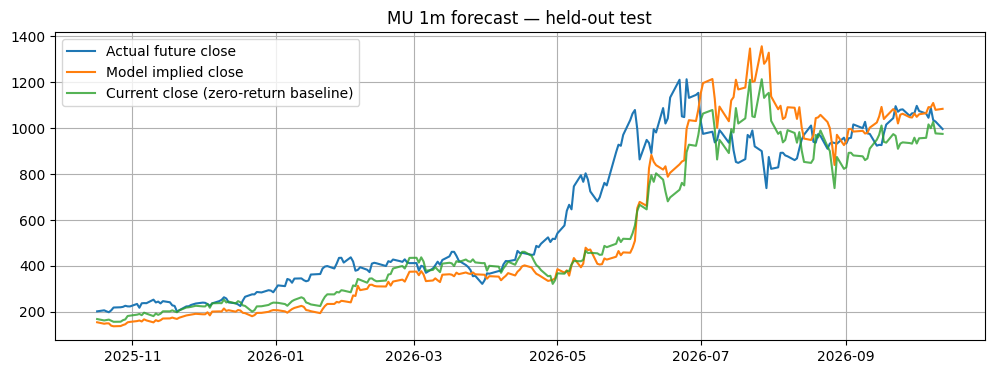

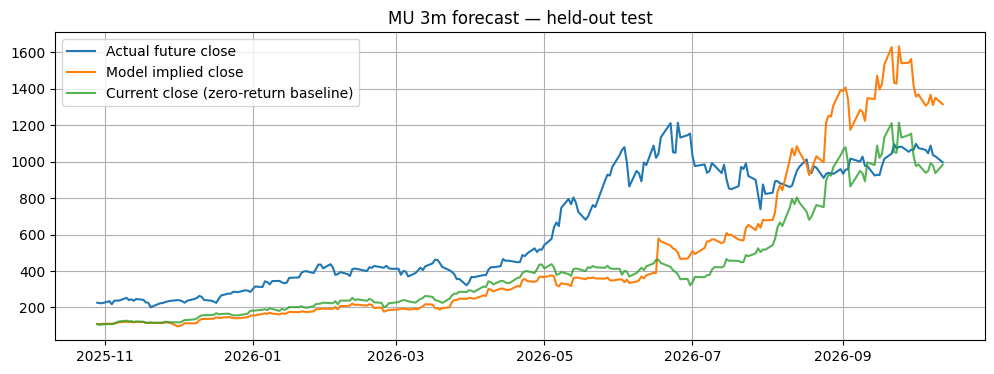

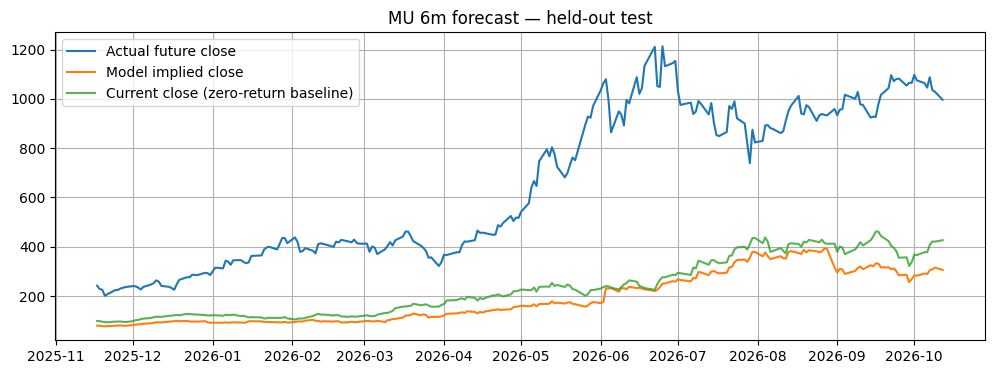

In [ ]:
if not results_df.empty:
    display(results_df[['horizon','feature_set','best_model','n_features','cv_rmse_mean','model_RMSE_log_return','best_baseline','best_baseline_RMSE_log_return','model_directional_accuracy','beats_best_baseline_RMSE']])
    for h in HORIZONS:
        sub=predictions_df[(predictions_df.horizon==h)&(predictions_df.feature_set=='C_price_macro_financials')].sort_values('date')
        if len(sub):
            plt.figure(figsize=(12,4))
            plt.plot(sub[f'target_date_{h}'],sub[f'target_close_{h}'],label='Actual future close')
            plt.plot(sub[f'target_date_{h}'],sub['predicted_close'],label='Model implied close')
            plt.plot(sub[f'target_date_{h}'],sub['close'],label='Current close (zero-return baseline)',alpha=.8)
            plt.title(f'MU {h} forecast — held-out test'); plt.legend(); plt.grid(True); plt.show()
else:
    print('No results. Check input files and parsed feature counts.')

## 10. บันทึกไฟล์ผลลัพธ์

จะได้ comparison, test predictions และ validation fold scores เพื่อนำมาอธิบายในรายงาน

In [ ]:
out='/content/mu_capstone_v5_outputs'; os.makedirs(out,exist_ok=True)
df.to_csv(f'{out}/mu_features_dataset_v5.csv',index=False)
results_df.to_csv(f'{out}/mu_model_comparison_v5.csv',index=False)
predictions_df.to_csv(f'{out}/mu_test_predictions_v5.csv',index=False)
cv_df.to_csv(f'{out}/mu_walkforward_cv_v5.csv',index=False)
print('Saved outputs to',out)
for name in ['mu_model_comparison_v5.csv','mu_test_predictions_v5.csv','mu_walkforward_cv_v5.csv']:
    files.download(f'{out}/{name}')

Saved outputs to /content/mu_capstone_v5_outputs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ข้อจำกัดที่ต้องรายงาน

- เป็นการพยากรณ์ผลตอบแทน ไม่ใช่คำแนะนำซื้อขาย และไม่ได้รับประกันผลตอบแทนจริง
- macro ถูกเลื่อนหนึ่งเดือนเป็น proxy ไม่ใช่ release-vintage data; real GDP ที่ความถี่รายเดือนอาจมีปัญหาความถี่/การแก้ไขย้อนหลัง ต้องตรวจแหล่งที่มา
- ข้อมูลการเงินถูกใช้หลัง reported date หรือ fiscal end + 60 วันเมื่อไม่มีวันประกาศ; ควรตรวจวันประกาศกับแหล่งต้นฉบับ
- ผลตอบแทน 3/6 เดือนใน test รายวันมีการซ้อนทับกัน ทำให้ observation ไม่เป็นอิสระ
- การชนะ baseline forecast ไม่เท่ากับชนะตลาด ต้องทำ trading backtest หลัง transaction costs และเทียบ buy-and-hold MU กับ semiconductor ETF
- ต้องตรวจวันที่ราคาผันผวนเกิน ±10% ว่าเป็นเหตุการณ์จริงหรือปัญหาจาก data source ก่อนสรุป